# 7. Costs, dilemmas and a health limit
> What happens when wrong decisions have different costs, why costs alone weaken health protection, and how a bound on missed restrictions limits that

Part of a temporary series explaining the scoring work on the `scoring-experiments` branch: 0 a primer on Bayesian statistics, 1 campaigns, 2 MCDM, 3 scoring, 4 the sawtooth, 5 from `bayes` to `voi`, 6 spatial correlation and placement, 7 costs and a health limit. `_explain_overview.ipynb` summarises the whole design.

Everything here uses toy units: a few numbers per unit, no rasters, and campaigns that run in seconds. The last section lists experiments to try. The plume results behind it are in "Two costs per unit" and "Health as a limit" in `_scoring_experiments.ipynb`, and the design in "Costs from MCDM" and "Health as a limit" in `scoring-design.md`.

The first cell runs the code cells of `07_scoring.ipynb` to load `expected_cost` and `voi`. It takes a few seconds.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from fastcore.nbio import read_nb
warnings.filterwarnings('ignore')
for c in read_nb('07_scoring.ipynb').cells:
    if c.cell_type == 'code': get_ipython().run_cell(c.source, silent=True).raise_error()

## Two kinds of error

The dashboard's rule restricts a unit when more than 10% of its samples are above the permissible level. It can go wrong in two ways:

- A needless restriction: the unit is restricted, but less than 10% of it is above the level. Farmers lose a harvest, a region its market reputation, a community its food.
- A missed restriction: the unit is not restricted, but more than 10% of it is above the level. People eat contaminated food.

So far `voi` counted both as one wrong decision. A nuclear response weighs one harm against the other, and the weights differ between units: a needless restriction of a valuable crop costs more than of a minor one. `voi` now takes three settings:

- `c_needless`: the cost of a needless restriction, one number or one per unit.
- `c_missed`: the cost of a missed restriction, one number or one per unit.
- `r`: the weight of a missed restriction against a needless one, for every unit.

With all three at 1, `voi` is exactly as before.

## More samples push a decision one way

This fact drives everything that follows. Take a unit with 6 samples, none above the level. It is not restricted. More samples cannot make it less restricted: they can only bring an exceedance that restricts it, rightly or wrongly. `expected_cost` with one cost set to 0 gives the probability of each kind of error after `m` more samples:

In [ ]:
def error_probs(k, n, ms=range(0, 9), a0=0.5, b0=0.5):
    "Probability of a needless and of a missed restriction for a unit with `k` of `n` samples above the level, after `m` more samples."
    return pd.DataFrame({'P(needless)': [expected_cost(k, n, m, a0, b0, c_needless=1., c_missed=0.) for m in ms],
                         'P(missed)': [expected_cost(k, n, m, a0, b0, c_needless=0., c_missed=1.) for m in ms]}, index=pd.Index(ms, name='m'))

clean = error_probs(0, 6)
assert clean['P(needless)'].iloc[0] == 0 and (clean['P(needless)'].iloc[1:] > 0).all()
clean.round(3)

,P(needless),P(missed)
m,,
0,0.000,0.267
1,0.023,0.214
2,0.044,0.173
3,0.065,0.142
4,0.007,0.216
5,0.011,0.196
6,0.016,0.177
7,0.021,0.160
8,0.027,0.144


The unit is not restricted now, so a needless restriction is impossible (0). Any added sample makes one possible, while the chance of a missed restriction falls. At 10 samples in total (`m` = 4), both jump back: the rule then needs 2 exceedances instead of 1. This is the sawtooth of notebook 4. A restricted unit is the mirror image. With 1 of 3 samples above the level, more samples can only lift the restriction, rightly or wrongly:

In [ ]:
error_probs(1, 3).round(3)

,P(needless),P(missed)
m,,
0,0.098,0.000
1,0.098,0.000
2,0.098,0.000
3,0.098,0.000
4,0.098,0.000
5,0.098,0.000
6,0.098,0.000
7,0.033,0.083
8,0.036,0.067


For the restricted unit, nothing changes for 6 more samples: with 1 exceedance, the measured share stays above 10% until 10 samples in total. From 7 more samples, the restriction can be lifted: P(needless) falls from 0.098 to 0.033, and P(missed) rises from 0 to 0.083. A look-ahead of 5 samples cannot see this, which is why `voi` now looks 10 ahead. Sampling an unrestricted unit looks for hidden contamination; sampling a restricted unit tries to lift a restriction.

## When a needless restriction is expensive

The expected cost of a unit's decision is `c_needless` times P(needless) plus `r` times `c_missed` times P(missed). `voi` gives samples where they lower it most. For the clean-looking unit, here is the expected cost as samples are added, with a needless restriction costing 1 and then 5:

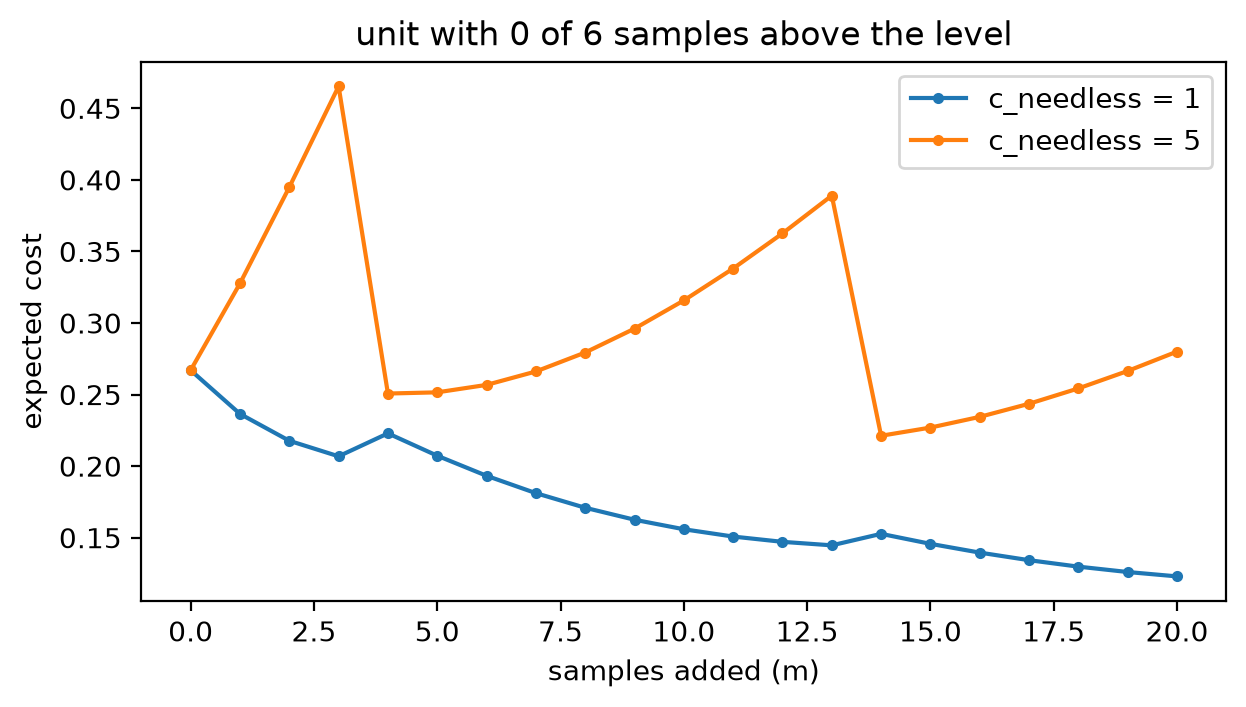

In [ ]:
ms = np.arange(0, 21)
fig, ax = plt.subplots(figsize=(7, 3.5))
for c in (1, 5):
    cost = [expected_cost(0, 6, m, c_needless=float(c)) for m in ms]
    ax.plot(ms, cost, 'o-', ms=3, label=f'c_needless = {c}')
ax.set(xlabel='samples added (m)', ylabel='expected cost', title='unit with 0 of 6 samples above the level')
ax.legend();

In [ ]:
costs5 = [expected_cost(0, 6, m, c_needless=5.) for m in ms]
assert max(costs5[1:]) > costs5[0]

With equal costs, more samples lower the expected cost: they find hidden contamination more often than they create a needless restriction. With a needless restriction costing 5, the curve goes up: each sample adds more expected cost from a possible needless restriction than it removes from a possible missed one. For `voi`, sampling this unit has negative value, so it gets nothing. Where economic value is high, `voi` stops looking.

## The ratio `r`

Five toy units, given as `k` of `n` samples above the level, and `voi` splitting 20 samples for three values of `r`. `toy_samples` builds the samples `voi` reads, with values 1 (above the level of 0.8) and 0:

In [ ]:
def toy_samples(units):
    "Samples of `units` (name: (k, n)), with `k` values of 1 and `n - k` values of 0."
    return pd.concat([pd.DataFrame({'value': [1.] * k + [0.] * (n - k)}, index=pd.Index([u] * n, name='loc_id')) for u, (k, n) in units.items() if n > 0]
                     or [pd.DataFrame({'value': []}, index=pd.Index([], name='loc_id'))])

def split(units, budget=20, **kw):
    "Samples `voi` gives each of `units` from `budget`, with `kw` passed to `voi`."
    return pd.Series(voi(0.8, min_total=0, **kw)(toy_samples(units), pd.DataFrame(index=pd.Index(list(units), name='loc_id')), budget,
                                                    np.random.default_rng(0)), index=list(units))

toy = {'fresh': (0, 0), 'clear low': (0, 6), 'near': (1, 9), 'early exceedance': (1, 3), 'borderline': (2, 18)}
pd.DataFrame({f'r = {r}': split(toy, r=r) for r in (0.25, 1, 4)}).assign(**{'k of n': [f'{k} of {n}' for k, n in toy.values()]})

,r = 0.25,r = 1,r = 4,k of n
fresh,3,5,8,0 of 0
clear low,0,2,12,0 of 6
near,8,7,0,1 of 9
early exceedance,7,0,0,1 of 3
borderline,2,6,0,2 of 18


With `r = 4`, a missed restriction weighs 4 times a needless one, and the samples go to the unrestricted units (`fresh`, `clear low`), to look for hidden contamination. With `r = 0.25`, they go to the restricted units (`near`, `early exceedance`), to try to lift restrictions. `r` decides which side `voi` looks on.

## Costs per unit

Two identical clean-looking units, `A` and `B`, each with 0 of 6 samples above the level, and a restricted unit `C` with 1 of 3. A needless restriction costs 5 in `A` and `C`, the valuable units, and 1 in `B`:

In [ ]:
units = {'A (valuable)': (0, 6), 'B': (0, 6), 'C (valuable)': (1, 3)}
valuable_cost = pd.Series([5., 1., 5.], index=pd.Index(list(units), name='loc_id'))
pd.DataFrame({'equal costs': split(units), 'needless costs 5 in A and C': split(units, c_needless=valuable_cost)})

,equal costs,needless costs 5 in A and C
A (valuable),10,0
B,10,10
C (valuable),0,10


With equal costs, `A` and `B` get the same. With the valuable costs, `A` gets nothing and `C` gets more: economic value moves samples away from the valuable clean-looking unit, and towards the valuable restricted one.

## A small campaign

`simulate` plays a strategy on toy units whose true share above the level is known: each sample is above the level with probability equal to the share. After the last round, each unit's decision is compared with its true share. Thirty units, with true shares spread from 0 to 25% around the 10% threshold, 4 rounds of 60 samples:

In [ ]:
def simulate(strategy, share, rounds=4, budget=60, seed=0):
    "Play `strategy` on toy units with true `share` above the level; return each unit's samples, decision and errors."
    rng = np.random.default_rng(seed)
    units = pd.DataFrame(index=pd.Index(share.index, name='loc_id'))
    samples = pd.DataFrame({'value': []}, index=pd.Index([], name='loc_id'))
    for _ in range(rounds):
        n = strategy(samples, units, budget, rng)
        new = [pd.DataFrame({'value': (rng.random(m) < share[u]).astype(float)}, index=pd.Index([u] * m, name='loc_id')) for u, m in zip(units.index, n) if m > 0]
        samples = pd.concat([samples, *new])
    res = pd.DataFrame({'n': samples.groupby(level=0).size(), 'k': (samples.value > 0.8).groupby(level=0).sum()}).reindex(units.index, fill_value=0).assign(share=share)
    res['restrict'] = res.k / res.n > 0.1
    return res.assign(needless=res.restrict & (res.share <= 0.1), missed=~res.restrict & (res.share > 0.1))

share = pd.Series(np.r_[np.linspace(0, 0.25, 15), np.linspace(0, 0.25, 15)], index=[f'u{i}' for i in range(30)])
valuable = share.index[:15]
simulate(voi(), share).head()

,n,k,share,restrict,needless,missed
loc_id,,,,,,
u0,9,0,0.000000,False,False,False
u1,15,1,0.017857,False,False,False
u2,9,0,0.035714,False,False,False
u3,17,2,0.053571,True,True,False
u4,9,0,0.071429,False,False,False


`errors` runs several seeds and counts the errors in the valuable units (the first 15) and the others:

In [ ]:
def errors(seeds=range(20), **kw):
    "Mean needless and missed restrictions, in the valuable units and the others, of `voi(**kw)` over `seeds`."
    rows = []
    for seed in seeds:
        res = simulate(voi(**kw), share, seed=seed)
        v = res.index.isin(valuable)
        rows.append({'needless, valuable': res.needless[v].sum(), 'missed, valuable': res.missed[v].sum(),
                     'needless, other': res.needless[~v].sum(), 'missed, other': res.missed[~v].sum(), 'samples, valuable': res.n[v].sum()})
    return pd.DataFrame(rows).mean()

Needless and missed restrictions over all 30 units, for five values of `r`:

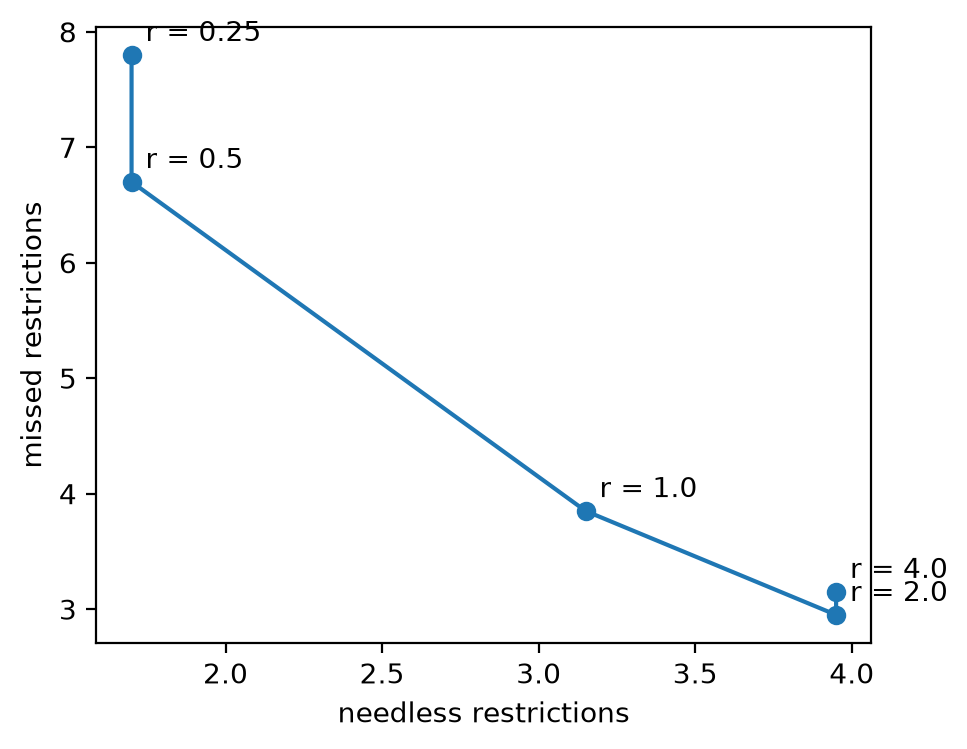

In [ ]:
rs = [0.25, 0.5, 1, 2, 4]
by_r = pd.DataFrame({r: errors(r=r) for r in rs}).T
by_r = by_r.assign(needless=by_r['needless, valuable'] + by_r['needless, other'], missed=by_r['missed, valuable'] + by_r['missed, other'])
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(by_r.needless, by_r.missed, 'o-')
for r, row in by_r.iterrows(): ax.annotate(f'r = {r}', (row.needless, row.missed), textcoords='offset points', xytext=(5, 5))
ax.set(xlabel='needless restrictions', ylabel='missed restrictions');

In [ ]:
by_r[['needless', 'missed', 'needless, valuable', 'missed, valuable']].round(2)

,needless,missed,"needless, valuable","missed, valuable"
0.25,1.70,7.80,1.00,3.75
0.50,1.70,6.70,0.90,3.20
1.00,3.15,3.85,1.75,1.65
2.00,3.95,2.95,2.00,1.40
4.00,3.95,3.15,2.00,1.50


From `r = 0.25` to `r = 1`, missed restrictions fall from 7.8 to 3.85 and needless ones rise from 1.7 to 3.15. Above `r = 2`, nothing changes: the remaining misses are units just above 10% that this budget cannot settle, whatever their weight. `r` is a lever with a limit set by the budget.

## The perverse incentive in a campaign

Now a needless restriction costs 5 in the valuable units and 1 in the others, with `r = 1`:

In [ ]:
cv = pd.Series(np.where(share.index.isin(valuable), 5., 1.), index=share.index)
incentive = pd.DataFrame({'equal costs': errors(), 'needless costs 5 in valuable units': errors(c_needless=cv)})
incentive.round(2)

,equal costs,needless costs 5 in valuable units
"needless, valuable",1.75,0.55
"missed, valuable",1.65,4.60
"needless, other",1.40,1.95
"missed, other",2.20,2.60
"samples, valuable",112.85,146.85


With a needless restriction costing 5 in the valuable units, needless restrictions there fall from 1.75 to 0.55, and missed ones rise from 1.65 to 4.6. The valuable units get more samples, not fewer (147 against 113), but the extra samples go to their restricted units, to try to lift restrictions. Their clean-looking units are sampled less, and contamination there goes unfound.

## Health as a limit

The proposed fix treats health as a limit, not a cost. `max_missed` is a bound on each unit's probability of a missed restriction. `voi` first gives samples to every unit above the bound, until it falls below it or more samples cannot lower it. Only then do the costs place the remaining samples.

How strict a bound can be depends on how fast a clean-looking unit's probability of a missed restriction falls. Without a prior, and with a prior worth 4 samples that marks the unit as clean (Beta(0.5, 4.5)):

In [ ]:
ns = [1, 3, 6, 8, 10, 15, 20, 30]
pd.DataFrame({'no prior': [expected_cost(0, n, 0, c_needless=0., c_missed=1.) for n in ns],
              'clean prior worth 4': [expected_cost(0, n, 0, 0.5, 4.5, c_needless=0., c_missed=1.) for n in ns]},
             index=pd.Index(ns, name='samples, none above the level')).round(3)

,no prior,clean prior worth 4
"samples, none above the level",,
1,0.621,0.310
3,0.426,0.231
6,0.267,0.153
8,0.201,0.118
10,0.153,0.091
15,0.081,0.049
20,0.044,0.027
30,0.013,0.008


Without a prior, a clean-looking unit reaches 20% after about 8 samples and 5% after about 20. A campaign often has fewer than 10 samples per unit, so a bound of 5% takes the whole budget and leaves nothing for the costs. A prior that marks the unit as clean lowers the probability from the start.

The same campaign, with the valuable costs and three bounds:

In [ ]:
bounds = pd.DataFrame({'equal costs': errors(), 'valuable costs, no bound': errors(c_needless=cv),
                       **{f'valuable costs, bound {b}': errors(c_needless=cv, max_missed=b) for b in (0.3, 0.2, 0.05)}})
bounds.round(2)

,equal costs,"valuable costs, no bound","valuable costs, bound 0.3","valuable costs, bound 0.2","valuable costs, bound 0.05"
"needless, valuable",1.75,0.55,0.90,1.00,2.00
"missed, valuable",1.65,4.60,3.65,3.15,1.40
"needless, other",1.40,1.95,1.75,1.75,1.95
"missed, other",2.20,2.60,2.15,2.35,1.65
"samples, valuable",112.85,146.85,149.30,150.00,119.25


Bounds of 0.3 and 0.2 lower missed restrictions in the valuable units to 3.65 and 3.15, without fully undoing the costs. A bound of 0.05 brings them to 1.4, below the 1.65 of equal costs, with 2.0 needless restrictions there.

Missed against needless restrictions in the valuable units, as the bound gets stricter:

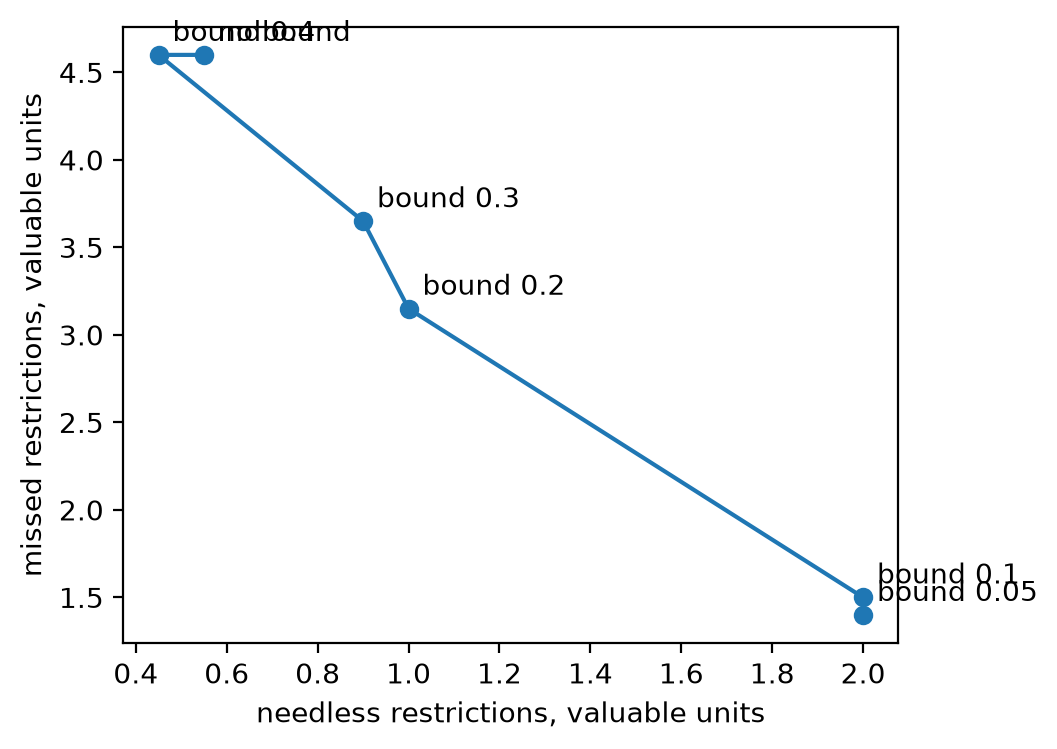

In [ ]:
bs = [None, 0.4, 0.3, 0.2, 0.1, 0.05]
curve = pd.DataFrame({str(b): errors(c_needless=cv, max_missed=b) for b in bs}).T
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(curve['needless, valuable'], curve['missed, valuable'], 'o-')
for b, row in curve.iterrows(): ax.annotate('no bound' if b == 'None' else f'bound {b}', (row['needless, valuable'], row['missed, valuable']), textcoords='offset points', xytext=(5, 5))
ax.set(xlabel='needless restrictions, valuable units', ylabel='missed restrictions, valuable units');

In [ ]:
curve[['needless, valuable', 'missed, valuable', 'samples, valuable']].round(2)

,"needless, valuable","missed, valuable","samples, valuable"
None,0.55,4.60,146.85
0.4,0.45,4.60,143.35
0.3,0.90,3.65,149.30
0.2,1.00,3.15,150.00
0.1,2.00,1.50,118.50
0.05,2.00,1.40,119.25


In this toy, a bound of 0.4 does nothing and the curve bends between 0.2 and 0.1. From 0.1, missed restrictions in the valuable units stay at about 1.5 and needless ones at 2.0: the bound then takes most of the budget, and the costs hardly act. The plume experiments gave the same shape, with the bend at a different place: it depends on the budget per unit and on the prior.

## Try it yourself

Each cell above runs in seconds. Things to change and watch:

- `r` in `errors(r=...)`: how far can missed restrictions fall, and what does each step cost in needless ones?
- The costs in `cv`: try 2 or 10 instead of 5, or make missed restrictions costly in some units with `c_missed=`.
- The bound in `errors(c_needless=cv, max_missed=...)`: where does the curve bend?
- The true shares in `share`: units far from 10% are easy; units at 8% or 12% are where every setting struggles.
- The budget and rounds in `simulate`: with more samples per unit, does a strict bound still crowd out the costs?
- Two units in `split`: a restricted and an unrestricted unit with the same costs, then with different costs. Predict which gets the samples, then check.

## What this means

- Costs make the dilemmas explicit, and `r` moves errors between the two kinds as intended.
- Used alone to allocate samples, costs weaken health protection where economic value is high: under the dashboard's rule, sampling a clean-looking unit can only restrict it, so `voi` stops looking where a restriction is expensive.
- A bound on each unit's probability of a missed restriction protects health first. Its level sets how much room is left for economic costs. The bound is a policy setting, like the permissible level, for decision makers and DSS4NAFA.